<a href="https://colab.research.google.com/github/Carlos-Biologist/Automated-_Detection_and_Tracking_Pinnipeds_UAVs_YOLO26_-_BoT-SORT/blob/main/Mallaria_Cell_COVID19_Radiography.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Malaria Cell Image Dataset**

In [1]:
# https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria

import kagglehub # Acessar datasets do Kaggle
import os # Funções para interagir com o sistema operacional, como navegar em diretórios, criar pastas, ou manipular arquivos
from PIL import Image # Abrir, manipular, e salvar imagens em diversos formatos
import numpy as np # Biblioteca para operações matemáticas em arrays e matrizes multidimensionais
import matplotlib.pyplot as plt # Criar visualizações gráficas

In [2]:
# Download dataset
path = kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cell-images-for-detecting-malaria' dataset.
Path to dataset files: /kaggle/input/cell-images-for-detecting-malaria


### **Passo 1: Carregar as Imagens das Pastas**

In [3]:
parasitado = '/root/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1/cell_images/Parasitized'
nao_parasitado = '/root/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1/cell_images/Uninfected'

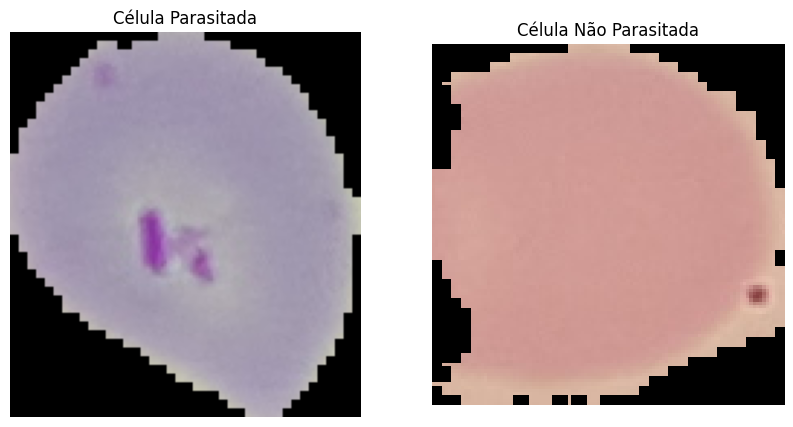

In [4]:
parasitado = os.path.join(path, 'cell_images', 'Parasitized')
nao_parasitado = os.path.join(path, 'cell_images', 'Uninfected')

# Selecionar uma imagem de cada pasta
img_parasitado = Image.open(os.path.join(parasitado, os.listdir(parasitado)[10]))
img_nao_parasitado = Image.open(os.path.join(nao_parasitado, os.listdir(nao_parasitado)[10]))

# Plotar as imagens
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_parasitado)
plt.title('Célula Parasitada')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_nao_parasitado)
plt.title('Célula Não Parasitada')
plt.axis('off')

plt.show()

In [5]:
# Lista para armazenar as imagens e os rótulos
images = []
labels = []

In [6]:
# Carregar imagens de células parasitadas
for filename in os.listdir(parasitado):
    file_path = os.path.join(parasitado, filename)
    if filename.endswith('.png'):  # Verifica se é uma imagem
        try:
            img = Image.open(file_path).convert('RGB')  # Converte para RGB
            img = img.resize((32, 32))  # Redimensiona a imagem para 32x32 (pode ajustar conforme necessário)
            images.append(np.array(img))
            labels.append(1)  # Rótulo 1 para parasitado
        except Exception as e:
            print(f'Erro ao carregar imagem {filename}: {e}')

In [7]:
# Carregar imagens de células não parasitadas
for filename in os.listdir(nao_parasitado):
    file_path = os.path.join(nao_parasitado, filename)
    if filename.endswith('.png'):  # Verifica se é uma imagem
        try:
            img = Image.open(file_path).convert('RGB')
            img = img.resize((32, 32))
            images.append(np.array(img))
            labels.append(0)  # Rótulo 0 para não parasitado
        except Exception as e:
            print(f'Erro ao carregar imagem {filename}: {e}')

In [8]:
# Converter para arrays NumPy
images = np.array(images)
labels = np.array(labels)

In [12]:
images.shape

(27558, 32, 32, 3)

In [13]:
labels.shape

(27558,)

### **Passo 2: Dividir em Conjuntos de Treino e Teste**

In [14]:
from sklearn.model_selection import train_test_split # Separar treino e teste
from tensorflow.keras.utils import to_categorical # transformar classes em categórico

In [15]:
# Dividir em treino (70%) e teste (30%)
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.3, random_state=42, stratify=labels)

In [16]:
# Normalizar as imagens
X_train = X_train / 255.0
X_test = X_test / 255.0

In [17]:
# Converter rótulos para categóricos
y_train = to_categorical(y_train, num_classes=2)
y_test = to_categorical(y_test, num_classes=2)

### **Passo 3: Construir e Treinar a Rede Neural Artificial**

In [10]:
from tensorflow import keras
from tensorflow.keras import Sequential # Importa o modelo Sequential, usado para empilhar camadas de redes neurais de forma linear, onde a saída de uma camada é a entrada da próxima.
from tensorflow.keras.layers import Dense, Flatten, Dropout # Importa a camada Dense, que é uma camada totalmente conectada onde cada neurônio recebe entrada de todos os neurônios da camada anterior.
                                                            # Importa a camada Flatten, que transforma uma entrada multidimensional (ex.: imagem) em um vetor unidimensional, útil para conectar camadas convolucionais com camadas densas.
                                                            # Importa a camada Dropout, que desativa aleatoriamente uma fração de neurônios durante o treinamento para reduzir o overfitting.

In [18]:
# Criar o modelo
model = Sequential([
    Flatten(input_shape=X_train.shape[1:]),         # Transformar entradas em um vetor unidimensional
    Dense(512, activation='relu'),                  # Camada oculta 1
    Dense(256, activation='relu'),                  # Camada oculta 2
    #Dense(128, activation='relu'),                  # Camada oculta 3
    #Dense(64, activation='relu'),                   # Camada oculta 4
    Dense(2, activation='sigmoid')                  # Camada de saída com  neurônios
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [19]:
# Compilar o modelo
model.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
# Treinar o modelo
history = model.fit(X_train, y_train, epochs=5, batch_size=156,
                    validation_data=(X_test, y_test), verbose=1)